## Building a Deep Convolutional Neural Network for FashionMNIST -- For Fun!

### Data Setup

In [52]:
# Imports
import torch
import torchvision
from torchvision import datasets, transforms
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim

import matplotlib.pyplot as plt
import datetime
import random

# Set Device
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Using Device {device}')

Using Device cuda


In [65]:
# Load data
data_path = 'data/'

fashion_train = datasets.FashionMNIST(data_path, train=True, download=True, transform=transforms.ToTensor())
fashion_val = datasets.FashionMNIST(data_path, train=False, download=True, transform=transforms.ToTensor())

# Names for corresponding class labels
class_labels = ['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat', 'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']

60000
10000
torch.Size([1, 28, 28]) torch.float32


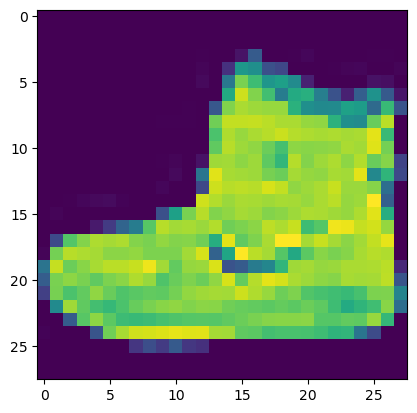

'Ankle boot'

In [3]:
# Examine Data

# Check dataset size
print(len(fashion_train))
print(len(fashion_val))

# Display Sample
img, label = fashion_train[0]

# Check image shape
print(img.shape, img.dtype) # 28 x 28 Grayscale imgs

%matplotlib inline
plt.imshow(img.permute(1, 2, 0))
plt.show()

class_lables[label]

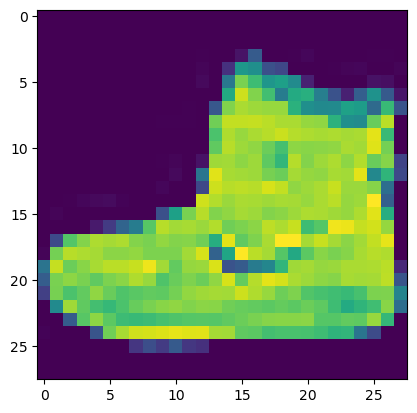

'Ankle boot'

In [25]:
# Normalize and Transform Dataset

imgs = torch.stack([img for img, _ in fashion_train], dim=0) # Create a batch dimension at idx 0 to stack images
imgs.shape
imgs = imgs.view(-1) #Flattening image to 1D Tensor - Since there is no chanels to keep (grayscale)
imgs.shape

mean = imgs.mean(dim=0).tolist() # Mean across all images and pixels 
std = imgs.std(dim=0).tolist() 

mean, std

transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(mean=mean, std=std)
])

fashion_train = datasets.FashionMNIST(data_path, train=True, download=False, transform=transform)
fashion_val = datasets.FashionMNIST(data_path, train=False, download=False, transform=transform)

img, label = fashion_train[0]
%matplotlib inline
plt.imshow(img.permute(1, 2, 0))
plt.show()

class_lables[label]

In [26]:
# Create Dataloader
train_loader = torch.utils.data.DataLoader(fashion_train, batch_size=256, shuffle=True, pin_memory=True, pin_memory_device=str(device))
val_loader = torch.utils.data.DataLoader(fashion_val, batch_size=258, shuffle=True, pin_memory=True, pin_memory_device=str(device))

### Building the (Deep) Model

In [27]:
# One Conv. Layer -- Building Block
class ConvNetBLock(nn.Module):
    def __init__(self, n_chans):
        # super().__init__()
        super(ConvNetBLock, self).__init__()
        self.conv = nn.Conv2d(n_chans, n_chans, kernel_size=3, padding='same', bias=False) # Remember: Batch norm cancels out bias -- so just disable 
        self.batch_norm = nn.BatchNorm2d(num_features=n_chans)

    def forward(self, x):
        out = self.conv(x) # Run Conv. on data to detect features
        out = self.batch_norm(out) # Normalize output before activation
        out = torch.relu(out)
        return out + x  # return layer output with skip connection

In [34]:
# Building the Network
class Net(nn.Module):
    def __init__(self, n_chans1=32, n_chans2 = 32, n_blocks=10):
        super().__init__()
        self.n_chans1 = n_chans1
        self.conv1 = nn.Conv2d(1, n_chans1, kernel_size=3, padding='same')
        self.convblock = nn.Sequential(
            *(ConvNetBLock(n_chans=n_chans1) for _ in range(n_blocks)) # Createing n_blocks individual and seperate NetConvBlock layers, each with their own parameters -- Unlike list method where all layers share same weights
        )
        self.fc1 = nn.Linear(n_chans1 * 7 * 7, n_chans2) # 28 x 28 image through 2 maxpool layer (/ 2) = 7
        self.fc2 = nn.Linear(n_chans2, 10)

    def forward(self, x):
        out = F.max_pool2d(torch.relu(self.conv1(x)), 2)
        out = self.convblock(out)
        out = F.max_pool2d(out, 2)

        # Flatten to 1D vector for FCN
        out = out.view(-1, self.n_chans1 * 7 * 7)
        out = self.fc1(out)
        out = self.fc2(out)

        return out

In [35]:
# Initalizing Network and moving to GPU
model = Net(n_blocks=1).to(device=device)

# Checking Model Params.
numel_list = [p.numel() for p in model.parameters()]
sum(numel_list)


60138

In [51]:
# Training Loop
def training_loop(n_epochs, model, optimizer, loss_fn, train_loader):
    for epoch in range(1, n_epochs + 1):
        train_loss = 0.0

        for image_batch, label_batch in train_loader:
            image_batch, label_batch = image_batch.to(device=device), label_batch.to(device=device)

            output_batch = model(image_batch)
            loss = loss_fn(output_batch, label_batch)

            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

            train_loss += loss.item()

            if epoch <= 3 or epoch % 10 == 0:
                print(f'\r {datetime.datetime.now()} EPOCH {epoch} Loss: {train_loss/len(train_loader)}', end='', flush=True) # Print updates same line
        if epoch <= 3 or epoch % 10 == 0:        
            print()  # Move to a new line after all epochs finish
        elif epoch == 4:
            print('...')

In [57]:
def validate_model(model, train_loader, val_loader):
    for name, loader in [('Train', train_loader), ('Validation', val_loader)]:
        correct = 0
        total = 0
        with torch.no_grad():
            for image_batch, label_batch in loader:
                image_batch, label_batch = image_batch.to(device=device), label_batch.to(device=device)


                output_batch = model(image_batch)
                _, predicted_batch = torch.max(output_batch, dim=1) # Return index with highest model confidance
                
                total += label_batch.shape[0]
                correct += int((predicted_batch == label_batch).sum()) # Count number of correctly identified samples

        print(f'{name} Accuracy: {(correct/total):.4f}')

In [50]:
model = Net(n_blocks=2).to(device=device)
learning_rate = 1e-3
optimizer = optim.Adam(model.parameters(), lr=learning_rate)
loss_fn = nn.CrossEntropyLoss()

training_loop(
    n_epochs=100,
    model=model,
    optimizer=optimizer,
    loss_fn=loss_fn,
    train_loader=train_loader
)

 2025-03-13 12:41:27.983655 EPOCH 1 Loss: 0.509239803920400945
 2025-03-13 12:41:34.981917 EPOCH 2 Loss: 0.2988669994663684743
 2025-03-13 12:41:42.210541 EPOCH 3 Loss: 0.2525307597632104645
 2025-03-13 12:42:31.185213 EPOCH 10 Loss: 0.1541311420658801345
 2025-03-13 12:43:41.957395 EPOCH 20 Loss: 0.08295773243174907654
 2025-03-13 12:44:45.028102 EPOCH 30 Loss: 0.05045090952610716666
 2025-03-13 12:45:48.746036 EPOCH 40 Loss: 0.02973815613683868656
 2025-03-13 12:46:53.302956 EPOCH 50 Loss: 0.04100475973310948643
 2025-03-13 12:48:00.394947 EPOCH 60 Loss: 0.01991909448840120365
 2025-03-13 12:49:10.099961 EPOCH 70 Loss: 0.01277199605420390454
 2025-03-13 12:50:18.843328 EPOCH 80 Loss: 0.00313559470994229575
 2025-03-13 12:51:30.590504 EPOCH 90 Loss: 7.474621884961999e-055
 2025-03-13 12:52:41.063632 EPOCH 100 Loss: 2.5885146251699126e-05


In [58]:
# Valiudate Model
validate_model(model, train_loader, val_loader)

Train Accuracy: 1.0000
Validation Accuracy: 0.9160


In [59]:
# Save Model
params_path = 'data/' + 'FashionCNN.pt'
torch.save(model.state_dict(), params_path)

Model Predicts Pullover with 97.46159315109253% Confidance


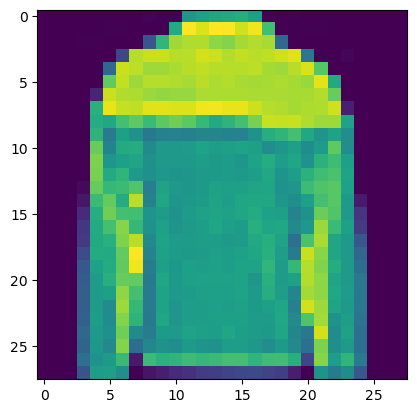

Actual Item: Pullover


In [121]:
# Test on an image
idx = random.randint(0, 9999)

img, label = fashion_val[idx]
img = img.to(device)

output = model(img.unsqueeze(0))
output = torch.softmax(output, dim=1)
confidance, prediction = torch.max(output, dim=1)

print(f'Model Predicts {class_labels[prediction]} with {confidance[0].item() * 100}% Confidance')

plt.imshow(img.cpu().detach().permute(1, 2, 0))
plt.show()
print(f'Actual Item: {class_labels[label]}')
